<div style="display:flex; align-items:center; gap:18px; text-align:left">

<div>
<p>Ingeniería en Información y Control de Gestión</p>
<p>Facultad de Economía y Negocios</p>
<p>Introducción a Machine Learning</p>
<p>Semana 09: PCA y K-means para descubrir estructura</p>
</div>
</div>

# 09 · PCA y K-means para descubrir estructura

> **La pregunta de hoy:** si nadie le dice al algoritmo qué buscar, ¿cómo sabemos que los segmentos que
> encuentra sirven?

Tres tiempos: **yo lo hago** (la preparación, y qué pasa si no se estandariza), **lo hacemos juntos**
(PCA y el plano de clientes) y **lo hacen ustedes** (agrupar, elegir cuántos grupos y perfilar cada uno).

## Preparación del entorno

En Colab estas librerías ya vienen instaladas; la celda queda para correr fuera de Colab. La siguiente
define `num`, que escribe las cifras con punto de miles y coma decimal.

In [1]:
%%capture
!pip install -q pandas numpy pyarrow scikit-learn matplotlib

In [2]:
from IPython.display import Markdown, display  # muestra frases con las cifras ya calculadas

def num(x, dec=0):
    # miles con punto, decimales con coma y el menos tipográfico
    texto = f'{x:,.{dec}f}'.replace(',', '@').replace('.', ',').replace('@', '.')
    return texto.replace('-', '−')

## Cargar datos

La tabla por cliente de una tienda en línea, `clientes_ventas.parquet`, leída con **pandas**.

<!-- contrato: accion=fijar-base -->

In [3]:
import os                # revisa si el archivo está en una carpeta local
import pandas as pd      # la librería de tablas: lee el archivo y lo deja como DataFrame

REPO = 'https://raw.githubusercontent.com/sebastiancontz/ust-introduccion-machine-learning-colab/main/ediciones/2026/datasets/'
BASE = '../datasets/' if os.path.exists('../datasets') else REPO

datos = pd.read_parquet(BASE + 'clientes_ventas.parquet')
print('registros y columnas:', datos.shape)
datos.head()

registros y columnas: (3314, 9)


,id_cliente,facturas_base,monto_base,productos_base,ticket_medio_base,recencia_dias,antiguedad_dias,mercado,facturas_futuras
0,12346,1,77183.60,1,77183.60,225,225,reino unido,0
1,12347,5,2790.86,82,558.17,29,267,exportacion,2
2,12348,3,1167.24,21,389.08,148,258,exportacion,1
3,12350,1,294.40,16,294.40,210,210,exportacion,0
4,12352,4,641.51,24,160.38,162,196,exportacion,3


## El encuadre: no hay respuesta que acertar

- **Unidad de observación:** un registro es un **cliente**.
- **Objetivo:** **no hay**. Nadie etiquetó a los clientes por tipo, así que no hay error que medir, ni
  partición, ni validación cruzada, ni conjunto de prueba.
- **Qué se busca:** resumir las columnas (PCA) y repartir a los clientes en grupos (K-means), y después
  juzgar si esos grupos sirven.

Se usan las **seis columnas numéricas** calculadas sobre nueve meses de compras: facturas, monto (en
libras), productos distintos, ticket medio (libras por factura), recencia (días desde la última compra) y
antigüedad (días desde la primera). `mercado` queda fuera porque es una categoría, y K-means trabaja con
distancias entre números; `facturas_futuras`, porque viene de después de esos nueve meses.

<!-- contrato: accion=elegir-columnas -->

In [4]:
COLUMNAS_LOG = ['facturas_base', 'monto_base', 'productos_base', 'ticket_medio_base']  # colas largas
COLUMNAS_DIAS = ['recencia_dias', 'antiguedad_dias']
COLUMNAS = COLUMNAS_LOG + COLUMNAS_DIAS

datos[COLUMNAS].agg(['min', 'median', 'max']).T

,min,median,max
facturas_base,1.0,2.000,126.00
monto_base,2.9,542.830,175782.94
productos_base,1.0,29.000,1188.00
ticket_medio_base,2.9,279.095,77183.60
recencia_dias,0.0,72.500,273.00
antiguedad_dias,0.0,184.000,273.00


Cada columna tiene su unidad y su rango: el monto llega a cientos de miles de libras y la recencia no
pasa de un año. Una diferencia de 100 significa cosas muy distintas en cada fila.

# Tiempo 1 · Yo lo hago

## La preparación: logaritmo y estandarizar, en un pipeline

Dos pasos, encadenados en un `Pipeline` como en la sesión 5:

1. **El logaritmo** en las cuatro columnas de colas largas: `FunctionTransformer(np.log1p)` aplica
   `log1p`, el logaritmo de 1 más el valor, para que un cero no rompa la cuenta. Recencia y antigüedad
   pasan sin cambio (`'passthrough'`): no tienen colas largas.
2. **Estandarizar** las seis con `StandardScaler`: a cada columna le **resta su promedio** y la **divide
   por su desviación**, así que queda con promedio 0 y desviación 1, contada en desviaciones.

`X_log` guarda los datos solo con el logaritmo, para la demostración; `Z`, con los dos pasos. La
preparación se define una vez y el pipeline recibe una copia nueva con `clone`.

<!-- contrato: accion=preparar -->

In [5]:
import numpy as np                                  # cálculo numérico
from sklearn.compose import ColumnTransformer       # prepara cada grupo de columnas a su manera
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline               # encadena los pasos
from sklearn.base import clone                      # copia sin ajustar de una preparación

con_log = ColumnTransformer([('log', FunctionTransformer(np.log1p), COLUMNAS_LOG),
                             ('dias', 'passthrough', COLUMNAS_DIAS)])
preparar = Pipeline([('log', clone(con_log)), ('estandarizar', StandardScaler())])
X_log = con_log.fit_transform(datos[COLUMNAS])     # con logaritmo, sin estandarizar
Z = preparar.fit_transform(datos[COLUMNAS])        # con logaritmo y estandarizado

### Cinco clientes, antes y después

Los cinco clientes más cercanos a los percentiles 5, 25, 50, 75 y 95 de la recencia. Arriba, sus seis
columnas en las unidades del archivo; abajo, las mismas seis ya preparadas.

In [6]:
cinco = []
for q in [0.05, 0.25, 0.5, 0.75, 0.95]:   # el cliente más cercano a cada percentil de recencia
    distancia = (datos['recencia_dias'] - datos['recencia_dias'].quantile(q)).abs()
    cinco.append(distancia.idxmin())

display(datos.loc[cinco, ['id_cliente'] + COLUMNAS])
display(pd.DataFrame(Z[cinco], columns=COLUMNAS, index=cinco).round(2))

,id_cliente,facturas_base,monto_base,productos_base,ticket_medio_base,recencia_dias,antiguedad_dias
46,12417,7,2483.52,131,354.79,6,257
70,12455,4,2077.36,66,519.34,27,196
55,12429,3,2482.88,61,827.63,72,265
141,12580,1,379.70,23,379.70,146,146
363,12967,2,1660.90,19,830.45,258,271


,facturas_base,monto_base,productos_base,ticket_medio_base,recencia_dias,antiguedad_dias
46,1.38,1.18,1.40,0.35,-1.12,1.04
70,0.62,1.03,0.77,0.85,-0.85,0.26
55,0.26,1.18,0.70,1.46,-0.26,1.15
141,-0.86,-0.36,-0.17,0.44,0.70,-0.38
363,-0.20,0.85,-0.34,1.46,2.16,1.22


Una columna, a mano: la recencia del último de los cinco. `std(ddof=0)` es la desviación que usa
`StandardScaler`.

In [7]:
promedio = datos['recencia_dias'].mean()
desviacion = datos['recencia_dias'].std(ddof=0)
dias = datos.loc[cinco[-1], 'recencia_dias']
display(Markdown(
    f'Recencia: promedio **{num(promedio, 1)}** días y desviación **{num(desviacion, 1)}**. El cliente de '
    f'{dias} días: ({dias} − {num(promedio, 1)}) / {num(desviacion, 1)} = **{num((dias - promedio) / desviacion, 2)}**, '
    f'lo mismo que entrega `StandardScaler`. Ese número ya no está en días: está en desviaciones.'
))

Recencia: promedio **92,3** días y desviación **76,7**. El cliente de 258 días: (258 − 92,3) / 76,7 = **2,16**, lo mismo que entrega `StandardScaler`. Ese número ya no está en días: está en desviaciones.

### Las seis, con promedio 0 y desviación 1

Estandarizar **no cambia la forma** de la distribución: una columna con cola larga la sigue teniendo.
Lo que acortó las colas fue el logaritmo; estandarizar solo cambió la unidad.

In [8]:
resumen_z = pd.DataFrame({'promedio': Z.mean(axis=0), 'desviación': Z.std(axis=0)}, index=COLUMNAS)
resumen_z.round(2) + 0.0   # + 0.0 evita que un −0,00 aparezca con signo

,promedio,desviación
facturas_base,0.0,1.0
monto_base,0.0,1.0
productos_base,0.0,1.0
ticket_medio_base,0.0,1.0
recencia_dias,0.0,1.0
antiguedad_dias,0.0,1.0


## La demostración: qué pasa si no se estandariza

Con el logaritmo ya aplicado, pero **sin estandarizar**: ¿cuánto aporta cada columna a la **varianza**
total, la medida de cuánto se diferencian los clientes?

`pd.Series` arma una **serie** de pandas: una sola columna con un índice. Acá, una varianza por columna,
con el nombre de cada columna como índice.

In [9]:
varianza = pd.Series(X_log.var(axis=0), index=COLUMNAS)
parte = 100 * varianza / varianza.sum()
display(parte.round(2).to_frame('% de la varianza total'))
display(Markdown(
    f'Recencia y antigüedad son el **{num(parte[COLUMNAS_DIAS].sum(), 2)} %** de la varianza total: no '
    f'porque digan más, sino porque se miden en días y las otras, en logaritmos.'
))

,% de la varianza total
facturas_base,0.00
monto_base,0.01
productos_base,0.01
ticket_medio_base,0.00
recencia_dias,49.28
antiguedad_dias,50.69


Recencia y antigüedad son el **99,97 %** de la varianza total: no porque digan más, sino porque se miden en días y las otras, en logaritmos.

### PCA sin estandarizar

`PCA` (análisis de componentes principales) construye columnas nuevas, los **componentes**, que son
mezclas de las originales con distintos pesos. El primero va en la dirección con más varianza. Los pesos
se llaman **cargas** y quedan en `components_`, un componente por fila. El signo de un componente es
arbitrario: lo que se lee es el tamaño de cada carga.

<!-- contrato: accion=pca-sin-estandarizar -->

In [10]:
from sklearn.decomposition import PCA   # componentes principales

pca_sin = PCA().fit(X_log)
cargas_sin = pd.Series(pca_sin.components_[0], index=COLUMNAS)
display(cargas_sin.round(2).to_frame('carga en el componente 1') + 0.0)
display(Markdown(
    f'El primer componente son las dos fechas: recencia pesa **{num(abs(cargas_sin["recencia_dias"]), 2)}** y '
    f'antigüedad **{num(abs(cargas_sin["antiguedad_dias"]), 2)}**. Las cuatro columnas de compras pesan, a lo '
    f'más, **{num(cargas_sin[COLUMNAS_LOG].abs().max(), 2)}**.'
))

,carga en el componente 1
facturas_base,0.00
monto_base,0.00
productos_base,0.00
ticket_medio_base,0.00
recencia_dias,0.69
antiguedad_dias,0.72


El primer componente son las dos fechas: recencia pesa **0,69** y antigüedad **0,72**. Las cuatro columnas de compras pesan, a lo más, **0,00**.

### K-means sin estandarizar

`KMeans` reparte a los clientes en **k grupos**: asigna cada cliente al centro más cercano, mueve cada
centro al promedio de su grupo y repite hasta que nadie cambia. `n_clusters` es k; `n_init=10` lo corre
desde diez puntos de partida y se queda con el mejor; `random_state=42` fija la semilla. `n_init` va
escrito porque su valor por defecto cambió entre versiones de scikit-learn; `random_state`, porque sin
él cada corrida parte de otro punto.

Por ahora, **tres grupos**: cuántos conviene se decide en el Tiempo 3. Se agrupa dos veces, sin
estandarizar y estandarizado.

<!-- contrato: accion=kmeans-sin-estandarizar -->

In [11]:
from sklearn.cluster import KMeans   # agrupa por distancia al centro de cada grupo

grupos_sin = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_log).labels_
grupos_con = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Z).labels_

¿Qué columnas separan a los grupos en cada caso? Para cada columna se mide **qué parte de sus
diferencias se explica por el grupo** del cliente: se reemplaza el valor de cada cliente por el promedio
de su grupo y se compara la varianza que queda con la total. Si es alta, la columna separa bien a los
grupos. `groupby(grupos).transform('mean')` hace ese reemplazo: devuelve, para cada cliente, el promedio
de su grupo. Las dos funciones de esta celda se usan desde acá hasta el final.

In [12]:
def parte_explicada(valores, grupos):
    # varianza de los promedios de grupo sobre la varianza total
    columna = pd.Series(valores)
    return columna.groupby(grupos).transform('mean').var(ddof=0) / columna.var(ddof=0)

def coincidencia(a, b):
    # parte de los clientes en el mismo grupo, emparejando cada grupo de a con el de b que más comparte
    # ponytail: dos grupos de a pueden emparejarse con el mismo de b; exacto cuando los repartos se parecen, como acá
    tabla = pd.crosstab(a, b)
    return tabla.max(axis=1).sum() / len(a)

In [13]:
separan = pd.DataFrame(index=COLUMNAS, columns=['sin estandarizar', 'estandarizado'], dtype=float)
for j, columna in enumerate(COLUMNAS):
    separan.loc[columna, 'sin estandarizar'] = 100 * parte_explicada(X_log[:, j], grupos_sin)
    separan.loc[columna, 'estandarizado'] = 100 * parte_explicada(X_log[:, j], grupos_con)
display(separan.round(0))

,sin estandarizar,estandarizado
facturas_base,49.0,55.0
monto_base,35.0,55.0
productos_base,24.0,42.0
ticket_medio_base,2.0,13.0
recencia_dias,75.0,65.0
antiguedad_dias,72.0,61.0


In [14]:
display(Markdown(
    f'Sin estandarizar, el **{num(100 * coincidencia(grupos_con, grupos_sin))} %** de los clientes queda en el '
    f'mismo grupo, pero el criterio cambió: las fechas explican el '
    f'**{num(separan.loc["recencia_dias", "sin estandarizar"])}** y el '
    f'**{num(separan.loc["antiguedad_dias", "sin estandarizar"])} %**, y el ticket medio baja de '
    f'{num(separan.loc["ticket_medio_base", "estandarizado"])} a '
    f'**{num(separan.loc["ticket_medio_base", "sin estandarizar"])} %**.'
))

Sin estandarizar, el **86 %** de los clientes queda en el mismo grupo, pero el criterio cambió: las fechas explican el **75** y el **72 %**, y el ticket medio baja de 13 a **2 %**.

Lo peligroso no es que salgan grupos absurdos: es que salen grupos **razonables** que miran casi solo
fechas, y nadie lo nota mirando el resultado. Por eso se estandariza **antes**, por decisión. Desde acá,
todo usa `Z`.

# Tiempo 2 · Lo hacemos juntos

## PCA sobre las columnas preparadas

`explained_variance_ratio_` guarda la **varianza explicada** de cada componente: la parte de la varianza
total que captura. Hay tantos componentes como columnas, y cada uno explica menos que el anterior.

<!-- contrato: accion=pca -->

In [15]:
pca = PCA().fit(Z)
componentes = []
for i in range(len(COLUMNAS)):
    componentes.append(f'componente {i + 1}')
explicada = pd.DataFrame({'% de la varianza': 100 * pca.explained_variance_ratio_}, index=componentes)
explicada['acumulada'] = explicada['% de la varianza'].cumsum()
explicada.round(1)

,% de la varianza,acumulada
componente 1,52.4,52.4
componente 2,21.6,74.1
componente 3,16.6,90.6
componente 4,7.0,97.6
componente 5,2.3,100.0
componente 6,0.0,100.0


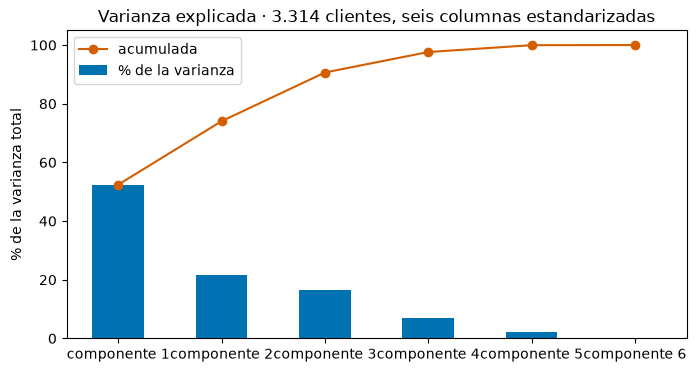

El primero explica el **52 %** y el segundo, el **22 %**: juntos, el **74 %**. Para mirar a los clientes en un plano, dos; el 26 % restante no se va a ver.

In [16]:
import matplotlib.pyplot as plt

ax = explicada['% de la varianza'].plot.bar(color='#0072B2', figsize=(8, 4), rot=0)
ax.plot(range(len(COLUMNAS)), explicada['acumulada'], color='#D55E00', marker='o', label='acumulada')
ax.set(ylabel='% de la varianza total', ylim=(0, 105),
       title=f'Varianza explicada · {num(len(datos))} clientes, seis columnas estandarizadas')
ax.legend()
plt.show()
display(Markdown(
    f'El primero explica el **{num(explicada.iloc[0, 0])} %** y el segundo, el **{num(explicada.iloc[1, 0])} %**: '
    f'juntos, el **{num(explicada.iloc[1, 1])} %**. Para mirar a los clientes en un plano, dos; el '
    f'{num(100 - explicada.iloc[1, 1])} % restante no se va a ver.'
))

## Las cargas: qué mezcla cada componente

Las **cargas** son los pesos de cada columna en la mezcla. Una carga grande, positiva o negativa, dice
que esa columna pesa en el componente. Los signos se leen **entre sí**: si el programa diera un
componente con todos los signos al revés, diría lo mismo.

<!-- contrato: accion=leer-cargas -->

In [17]:
cargas = pd.DataFrame(pca.components_[:2].T, index=COLUMNAS, columns=['componente 1', 'componente 2'])
display(cargas.round(2) + 0.0)

pesan_1 = cargas['componente 1'].abs().sort_values(ascending=False).index[:3]
pesan_2 = cargas['componente 2'].abs().sort_values(ascending=False).index[:2]
display(Markdown(f'Pesan más en el componente 1: **{", ".join(pesan_1)}**. En el 2: **{" y ".join(pesan_2)}**.'))

,componente 1,componente 2
facturas_base,0.48,0.11
monto_base,0.54,0.00
productos_base,0.46,0.00
ticket_medio_base,0.34,-0.12
recencia_dias,-0.31,0.62
antiguedad_dias,0.23,0.77


Pesan más en el componente 1: **monto_base, facturas_base, productos_base**. En el 2: **antiguedad_dias y recencia_dias**.

El componente 1 sube con facturas, monto y productos: es **volumen**, cuánto compra el cliente. El 2 sube
con recencia y antigüedad: es **tiempo**, hace cuánto llegó y hace cuánto no vuelve. No siempre los
componentes admiten una lectura así de limpia; cuando no, no se les inventa un nombre.

## El plano de los clientes

Cada cliente queda en dos números: su posición en el componente 1 y en el 2. Se marcan tres clientes que
aparecen en la teoría, **A**, **B** y **C**.

<!-- contrato: accion=plano -->

In [18]:
plano = pca.transform(Z)[:, :2]   # los dos primeros componentes de cada cliente
tres = {'A': 14732, 'B': 14754, 'C': 15840}
filas_tres = {}
for letra in tres:
    filas_tres[letra] = datos.index[datos['id_cliente'] == tres[letra]][0]
datos.loc[list(filas_tres.values()), ['id_cliente'] + COLUMNAS]

,id_cliente,facturas_base,monto_base,productos_base,ticket_medio_base,recencia_dias,antiguedad_dias
1368,14732,5,1618.30,72,323.66,43,239
1380,14754,1,228.27,15,228.27,195,195
1978,15840,1,241.74,17,241.74,72,72


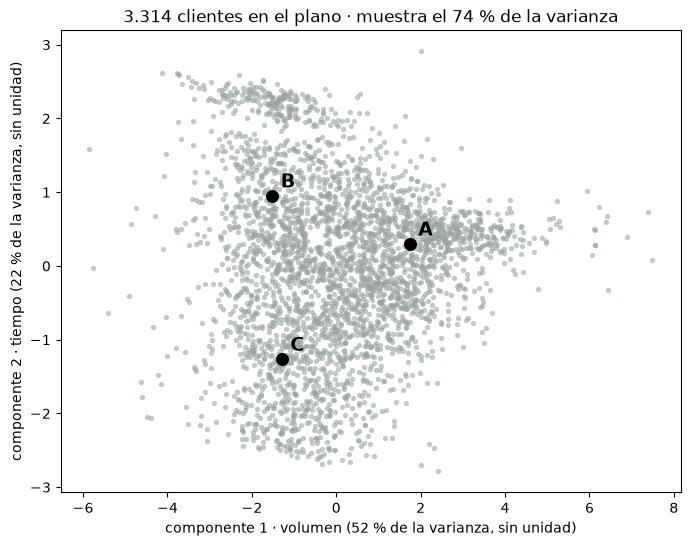

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(plano[:, 0], plano[:, 1], s=8, color='#9aa5a3', alpha=0.5)
for letra in filas_tres:
    x, y = plano[filas_tres[letra]]
    ax.scatter(x, y, s=70, color='black')
    ax.annotate(letra, (x, y), xytext=(6, 6), textcoords='offset points', fontsize=14, weight='bold')
ax.set(xlabel=f'componente 1 · volumen ({num(explicada.iloc[0, 0])} % de la varianza, sin unidad)',
       ylabel=f'componente 2 · tiempo ({num(explicada.iloc[1, 0])} % de la varianza, sin unidad)',
       title=f'{num(len(datos))} clientes en el plano · muestra el {num(explicada.iloc[1, 1])} % de la varianza')
plt.show()

**A** compra mucho y volvió hace poco; **B** compró una vez y hace mucho que no vuelve; **C** también
compró una vez, pero llegó hace poco. Si en su computador el plano sale espejado, es el signo arbitrario:
dice lo mismo.

La nube es **una sola**: no se ven grupos separados por espacio vacío. K-means no va a encontrar grupos
que ya estaban aparte; va a **repartir** esta nube.

# Tiempo 3 · Lo hacen ustedes

## La actividad: ¿cuántos segmentos, y para qué sirve cada uno?

Marketing quiere tratar distinto a distintos tipos de clientes. Con `Z` ya preparado:

1. **Recorran k de 1 a 8**: la inercia y el silhouette de cada uno.
2. **Grafiquen el codo y el silhouette.**
3. **Elijan un número de grupos** y defiéndanlo con los dos.
4. **Agrupen** con ese número y **coloreen el plano**.
5. **Comprueben** que el reparto se repite con otras semillas.
6. **Perfilen** cada grupo con sus medianas, en las unidades del archivo.
7. **Pónganle nombre y una acción** a cada segmento.

**Criterio de éxito:** defienden el número de grupos con el codo **y** el silhouette, aunque no
coincidan, y describen cada segmento con sus variables y una acción distinta de las demás.

**Evidencia observable:** la tabla de codo y silhouette con su elección, el plano coloreado y la tabla de
perfiles con un nombre y una acción por segmento; el **feedback formativo** llega en la puesta en común.

<p align="center"></p>

### Paso 1 · Recorrer k de 1 a 8

- `inertia_` es la **inercia**: la suma, sobre todos los clientes, de la distancia al cuadrado a su
  centroide, el promedio de su grupo. Baja **siempre** al sumar un grupo.
- `silhouette_score` promedia el **silhouette** (silueta) de cada cliente: compara su distancia promedio a
  su grupo con la del grupo vecino. Va de −1 a 1, y cerca de 1 es mejor. Necesita al menos dos grupos.

El ciclo tarda unos segundos.

<!-- contrato: accion=recorrer-k -->

In [20]:
from sklearn.metrics import silhouette_score   # promedio del silhouette de todos los clientes

filas = []
for k in range(1, 9):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    silueta = silhouette_score(Z, modelo.labels_) if k > 1 else np.nan  # con un grupo no hay vecino
    filas.append({'k': k, 'inercia': modelo.inertia_, 'silhouette': silueta})
recorrido = pd.DataFrame(filas).set_index('k')
recorrido['cuánto baja (%)'] = 100 * (1 - recorrido['inercia'] / recorrido['inercia'].shift())
recorrido.round(2)

,inercia,silhouette,cuánto baja (%)
k,,,
1,19884.00,NaN,NaN
2,12913.90,0.31,35.05
3,10246.76,0.29,20.65
4,8859.75,0.24,13.54
5,7756.84,0.24,12.45
6,7040.98,0.24,9.23
7,6544.46,0.22,7.05
8,6113.49,0.21,6.59


### Paso 2 · El codo y el silhouette

El **codo** es el punto desde el cual sumar un grupo ayuda poco: se busca dónde la caída de la inercia
cambia de ritmo, no su valor más bajo.

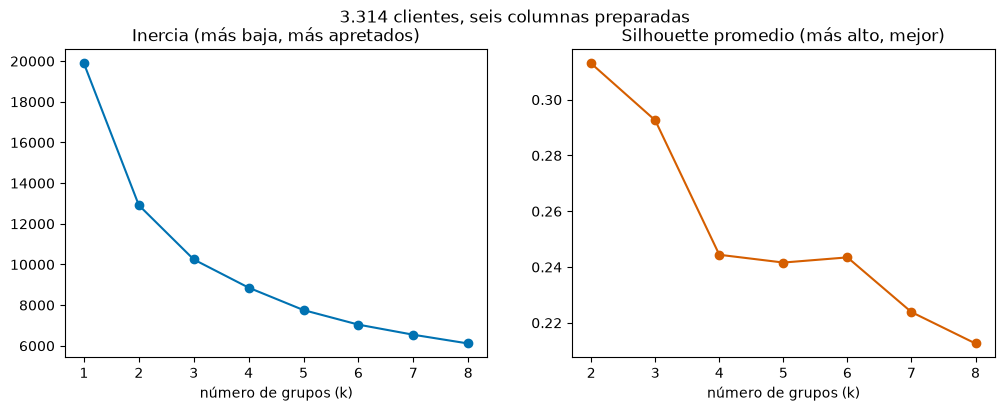

In [21]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12, 4))
recorrido['inercia'].plot(ax=ax_a, marker='o', color='#0072B2', title='Inercia (más baja, más apretados)')
recorrido['silhouette'].plot(ax=ax_b, marker='o', color='#D55E00', title='Silhouette promedio (más alto, mejor)')
for ax in (ax_a, ax_b):
    ax.set_xlabel('número de grupos (k)')
fig.suptitle(f'{num(len(datos))} clientes, seis columnas preparadas')
plt.show()

In [22]:
mejor_silueta = recorrido['silhouette'].idxmax()
display(Markdown(
    f'El silhouette más alto es con **{mejor_silueta}** grupos ({num(recorrido.loc[mejor_silueta, "silhouette"], 2)}); '
    f'con tres, {num(recorrido.loc[3, "silhouette"], 2)}, y con cuatro, {num(recorrido.loc[4, "silhouette"], 2)}. '
    f'La inercia baja un {num(recorrido.loc[3, "cuánto baja (%)"])} % al pasar de dos a tres grupos y un '
    f'{num(recorrido.loc[4, "cuánto baja (%)"])} % al pasar de tres a cuatro.'
))

El silhouette más alto es con **2** grupos (0,31); con tres, 0,29, y con cuatro, 0,24. La inercia baja un 21 % al pasar de dos a tres grupos y un 14 % al pasar de tres a cuatro.

### Paso 3 · Elegir el número de grupos

El codo y el silhouette **pueden no coincidir**, y entonces decide también para qué servirán los grupos.
La celda trae **3**, el número que defendió la teoría. Pueden cambiarlo: todo lo que sigue se recalcula.
Dos o tres son defendibles si dicen por qué; cuatro exige mostrar qué segmento nuevo aparece y qué
acción distinta pide.

<!-- contrato: accion=elegir-k -->

In [23]:
k_elegido = 3   # cámbienlo si defienden otro número, entre 2 y 8

### Paso 4 · Agrupar y colorear el plano

Los grupos se numeran **por tamaño**, del más grande al más chico. El número que pone `KMeans` es
arbitrario y puede cambiar entre versiones de scikit-learn aunque los grupos sean los mismos.

<!-- contrato: accion=agrupar -->

In [24]:
segmentador = KMeans(n_clusters=k_elegido, n_init=10, random_state=42).fit(Z)
por_tamano = pd.Series(segmentador.labels_).value_counts().index   # del grupo más grande al más chico
nombre_grupo = {}
for orden, etiqueta in enumerate(por_tamano):
    nombre_grupo[etiqueta] = f'grupo {orden + 1}'
grupo = pd.Series(segmentador.labels_).map(nombre_grupo)
grupo.value_counts().sort_index().to_frame('clientes')

,clientes
grupo 1,1245
grupo 2,1051
grupo 3,1018


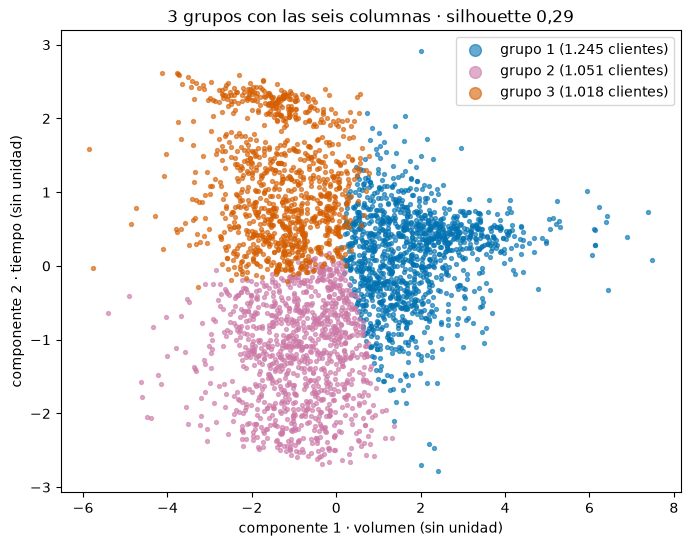

In [25]:
COLORES = ['#0072B2', '#CC79A7', '#D55E00', '#E69F00', '#56B4E9', '#009E73', '#000000', '#999999']
fig, ax = plt.subplots(figsize=(8, 6))
for i, nombre in enumerate(sorted(grupo.unique())):
    en_grupo = (grupo == nombre).to_numpy()
    ax.scatter(plano[en_grupo, 0], plano[en_grupo, 1], s=8, alpha=0.6, color=COLORES[i],
               label=f'{nombre} ({num(en_grupo.sum())} clientes)')
ax.set(xlabel='componente 1 · volumen (sin unidad)', ylabel='componente 2 · tiempo (sin unidad)',
       title=f'{k_elegido} grupos con las seis columnas · silhouette {num(recorrido.loc[k_elegido, "silhouette"], 2)}')
ax.legend(markerscale=3)
plt.show()

Un silhouette de 0,3 o menos indica una **estructura débil**: los grupos son zonas de una sola nube que
se tocan en sus bordes, no islas. K-means **repartió** la nube; que el reparto sirva lo deciden los
pasos que siguen.

### Paso 5 · ¿Se repite con otras semillas?

Se agrupa de nuevo con cinco semillas distintas y se cuenta qué parte de los clientes cae en el mismo
grupo. Fijar la semilla hace que el resultado se repita; cambiarla a propósito comprueba que no dependa
de ella.

<!-- contrato: accion=otras-semillas -->

In [26]:
repeticion = []
for semilla in range(5):
    otro = KMeans(n_clusters=k_elegido, n_init=10, random_state=semilla).fit(Z)
    repeticion.append(100 * coincidencia(segmentador.labels_, otro.labels_))
display(Markdown(f'Con cinco semillas distintas, al menos el **{num(min(repeticion), 2)} %** de los '
                 f'clientes cae en el mismo grupo.'))

Con cinco semillas distintas, al menos el **99,88 %** de los clientes cae en el mismo grupo.

### Paso 6 · Perfilar cada grupo

El perfil va en las **unidades del archivo**, no en las estandarizadas: «182 días» se entiende; «1,2
desviaciones», no. La **mediana** de cada columna por grupo, el tamaño de cada uno —`insert` lo agrega
como primera columna— y, al final, la mediana de todos los clientes para comparar.

<!-- contrato: accion=perfilar -->

In [27]:
perfil = datos[COLUMNAS].groupby(grupo).median()
perfil.loc['todos'] = datos[COLUMNAS].median()   # la mediana de todos, para comparar
clientes = grupo.value_counts()
clientes['todos'] = len(datos)
perfil.insert(0, 'clientes', clientes)
perfil.round(0)

,clientes,facturas_base,monto_base,productos_base,ticket_medio_base,recencia_dias,antiguedad_dias
grupo 1,1245,5.0,1655.0,70.0,356.0,31.0,233.0
grupo 2,1051,1.0,341.0,19.0,241.0,56.0,85.0
grupo 3,1018,1.0,283.0,15.0,203.0,182.0,211.0
todos,3314,2.0,543.0,29.0,279.0,72.0,184.0


### Paso 7 · Nombre y acción

Un segmento sirve si se puede **describir**, es **lo bastante grande** para actuar sobre él y pide algo
**distinto** de los demás. Si dos grupos piden la misma acción, para la organización son uno solo.
Completen la tabla, una fila por grupo; si eligieron otro número, agreguen o borren filas:

| Grupo | Nombre | Qué lo distingue | Una acción posible |
|:--|:--|:--|:--|
| grupo 1 | | | |
| grupo 2 | | | |
| grupo 3 | | | |

Y la defensa del número de grupos, en dos líneas:

1. Qué dicen el codo y el silhouette:
2. Por qué este número sirve más que el otro candidato:

# Cierre

## Cómo saber si los segmentos sirven

Sin objetivo no hay error que medir: lo que reemplaza a la cifra es un **criterio**. Sirven si la
preparación no dejó que la escala decidiera, si el número de grupos se defiende con más de un criterio
y se repite con otras semillas, y si cada segmento se describe y pide una acción distinta.

PCA y K-means son **independientes**: hoy PCA sirvió para mirar y K-means agrupó con las seis columnas.
Reducir antes de agrupar es una decisión, no un paso obligatorio.

## Atribución de datos

- **Creador:** Chen, D. (2012)
- **Fuente:** [UCI Machine Learning Repository — *Online Retail II*, dataset 502](https://archive.ics.uci.edu/dataset/502/online+retail+ii)
- **Licencia:** [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)
- **Modificación:** obra derivada en tres pasos. Las columnas originales se renombraron al español en
  `snake_case`; se aplicaron las siete decisiones de limpieza de la sesión 4; y
  se agregaron por cliente nueve meses de compras hasta una
  fecha fija, quedando 3.314 registros y 9 columnas. Esta sesión usa seis de ellas.